<a href="https://colab.research.google.com/github/09StevenG/2022-ii-tutorial-git-repo-ejemplo/blob/main/Semana_04_pr%C3%A1ctica_DEM_y_rasters_sept_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#instalar las librerias necesarias

!pip install -q rasterio # si no esta instalado

In [ ]:
import rasterio

In [ ]:
#importamos las librerias que necesitamos
import os #sirve para interactuar con el equipo (descargar el geotiff )
import math #sirve para calculos matematicos
import numpy as np #necesario para manejar rasters despues de leido
import pandas as pd #sirve para manipula datos
import geopandas as gpd #para archivo de datos geográficos
import matplotlib.pyplot as plt #para graficar

import rasterio ##manipulacion de rasters
from rasterio.windows import from_bounds #funciones para buscar limites de raser
from rasterio.merge import merge #para unir
from rasterio.plot import show #para poder pre-visualizar


In [ ]:
print("rasterio", rasterio.__version__)

rasterio 1.5.1


In [ ]:
DEM_CLASE = "https://raw.githubusercontent.com/navilaufm/geodata/main/mde-fill_4326.tif"

dem = rasterio.open(DEM_CLASE)

In [ ]:
# dem.meta #ver los atributos del raster recien abierto

In [ ]:
print("Dimensiones :", dem.width, "x", dem.height, "(columnas x filas)")
print("Bandas      :", dem.count)
print("Tipo de dato:", dem.dtypes[0])
print("CRS         :", dem.crs)
print("Valor nulo  :", dem.nodata)
print("Extensión   :", dem.bounds)
print("transform   :", dem.transform)

Dimensiones : 2060 x 1672 (columnas x filas)
Bandas      : 1
Tipo de dato: float32
CRS         : EPSG:4326
Valor nulo  : -99999.0
Extensión   : BoundingBox(left=-86.73675055641782, bottom=13.252049445084776, right=-86.17873232074919, top=13.70496521694785)
transform   : | 0.00, 0.00,-86.74|
| 0.00,-0.00, 13.70|
| 0.00, 0.00, 1.00|


In [ ]:
dem.close()      # buena práctica: cerrar lo que se abre

In [ ]:
with rasterio.open(DEM_CLASE) as dem:
    print("Abierto:", dem.name.split("/")[-1])
    print("Cerrado automáticamente al salir del bloque")
    print("Dimensiones :", dem.width, "x", dem.height, "(columnas x filas)")
    print("Bandas      :", dem.count)
    print("Tipo de dato:", dem.dtypes[0])
    print("CRS         :", dem.crs)
    print("Valor nulo  :", dem.nodata)
    print("Extensión   :", dem.bounds)
    print("transform   :", dem.transform)

print("¿Sigue abierto?", not dem.closed)

Abierto: mde-fill_4326.tif
Cerrado automáticamente al salir del bloque
Dimensiones : 2060 x 1672 (columnas x filas)
Bandas      : 1
Tipo de dato: float32
CRS         : EPSG:4326
Valor nulo  : -99999.0
Extensión   : BoundingBox(left=-86.73675055641782, bottom=13.252049445084776, right=-86.17873232074919, top=13.70496521694785)
transform   : | 0.00, 0.00,-86.74|
| 0.00,-0.00, 13.70|
| 0.00, 0.00, 1.00|
¿Sigue abierto? False


In [ ]:
#leer el transform para determinar el tamaño de cada celda y donde inicia el raster
with rasterio.open(DEM_CLASE) as dem:
    t = dem.transform
    print(f"Ancho de celda : {t.a:.6f} grados")
    print(f"Ancho de celda en metros : {t.a*111320:.6f} metros")
    print(f"Alto de celda  : {t.e:.6f} grados  (negativo: las filas van hacia abajo)")
    print(f"Esquina sup-izq: {t.c:.4f}, {t.f:.4f}")
    print()
    print(f"Es decir, unos {t.a * 111320:.0f} metros de lado")


Ancho de celda : 0.000271 grados
Ancho de celda en metros : 30.154655 metros
Alto de celda  : -0.000271 grados  (negativo: las filas van hacia abajo)
Esquina sup-izq: -86.7368, 13.7050

Es decir, unos 30 metros de lado


In [ ]:
with rasterio.open(DEM_CLASE) as dem:
    print("La celda (0, 0) está en:", dem.xy(0, 0))
    print("La celda del centro   :", dem.xy(dem.height // 2, dem.width // 2))
    print()
    fila, col = dem.index(-86.50, 13.50)
    print(f"La coordenada (-86.50, 13.50) cae en la fila {fila}, columna {col}")

La celda (0, 0) está en: (np.float64(-86.73661511509847), np.float64(13.704829775628513))
La celda del centro   : (np.float64(-86.45760599726417), np.float64(13.478371889696975))

La coordenada (-86.50, 13.50) cae en la fila 756, columna 873


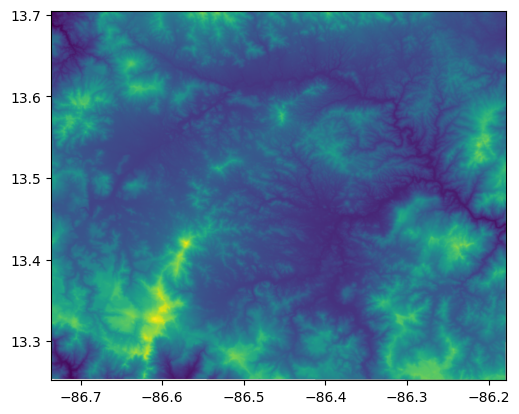

Tipo : <class 'numpy.ndarray'>
Forma: (1672, 2060) → 3,444,320 celdas
Un pedacito de la matriz:
[[709.9167  706.0833  702.5014  702.14667]
 [715.1389  710.69446 705.47797 702.5033 ]
 [723.30554 718.5278  712.7514  708.2022 ]
 [736.4722  730.2778  723.3889  718.3889 ]]


In [ ]:
#hasta ahora solo hemos trabajado con la estructura del raster, pero lo que nos interesa es la data, que se encuentra en las bandas
with rasterio.open(DEM_CLASE) as dem:
    z = dem.read(1)
    nodata = dem.nodata
    bounds = dem.bounds
    show(dem) #vista previa del raster con todas las bandas

print("Tipo :", type(z))
print("Forma:", z.shape, "→", f"{z.size:,} celdas")
print("Un pedacito de la matriz:")
print(z[800:804, 1000:1004])


In [ ]:
bounds

BoundingBox(left=-86.73675055641782, bottom=13.252049445084776, right=-86.17873232074919, top=13.70496521694785)

In [ ]:
type(z) #datos de la banda 1 extraidos del raster con rasterio

numpy.ndarray

In [ ]:
validos = z[z != nodata]

print(f"Celdas totales : {z.size:,}")
print(f"Celdas con dato: {validos.size:,}")
datos_nulos = z.size - validos.size
print(f"Celdas Sin dato restando: {datos_nulos:,}")

print(f"Celdas nulas filtrando  : {(z == nodata).sum():,}")
print(f"Porcentaje nulo: {(z == nodata).sum() / z.size * 100:.2f} %")

Celdas totales : 3,444,320
Celdas con dato: 3,428,091
Celdas Sin dato restando: 16,229
Celdas nulas filtrando  : 16,229
Porcentaje nulo: 0.47 %


In [ ]:
# que pasa si se olvidan de los nulos
print("Mínimo SIN apartar los nulos:", z.min())
print("Mínimo apartándolos         :", validos.min())

Mínimo SIN apartar los nulos: -99999.0
Mínimo apartándolos         : 346.62814


In [ ]:
#entonces ya con datos válidos podemos extrar mas información
print(f"Elevación mínima : {validos.min():.0f} msnm")
print(f"Elevación máxima : {validos.max():.0f} msnm")
print(f"Elevación media  : {validos.mean():.0f} msnm")
print(f"Desviación       : {validos.std():.0f} m")
print()
print(f"Desnivel total   : {validos.max() - validos.min():.0f} m")

Elevación mínima : 347 msnm
Elevación máxima : 1742 msnm
Elevación media  : 829 msnm
Desviación       : 208 m

Desnivel total   : 1395 m


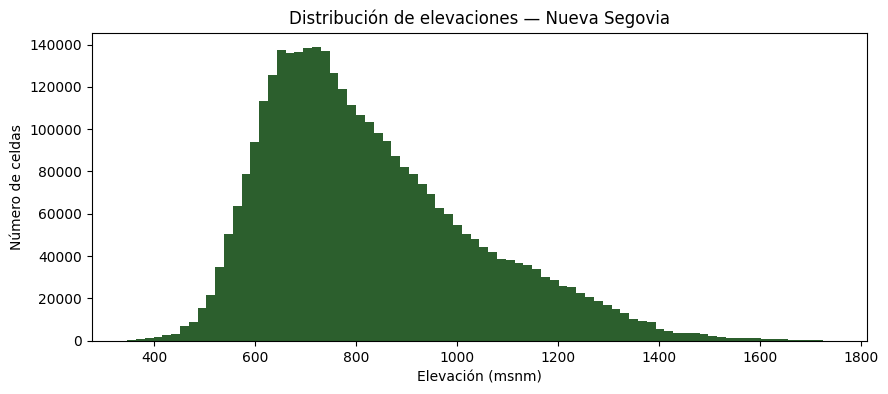

In [ ]:
#histograma de las alturas

plt.figure(figsize=(10, 4))
plt.hist(validos, bins=80, color="#2C5F2D")
plt.xlabel("Elevación (msnm)")
plt.ylabel("Número de celdas")
plt.title("Distribución de elevaciones — Nueva Segovia")
plt.show()

[-86.73675055641782, -86.17873232074919, 13.252049445084776, 13.70496521694785]


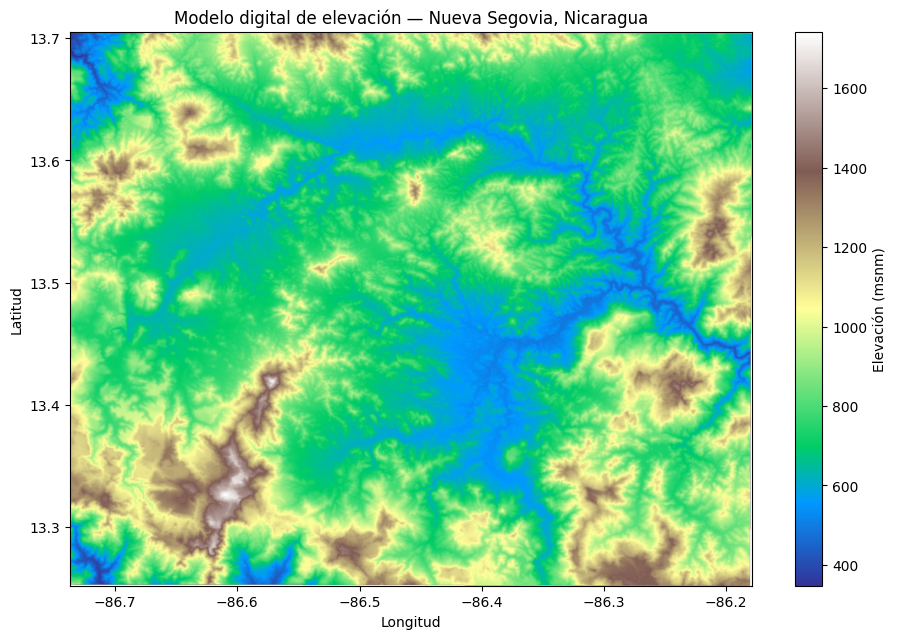

In [ ]:
zm = np.ma.masked_equal(z, nodata)

extent = [bounds.left, bounds.right, bounds.bottom, bounds.top]
print(extent)

plt.figure(figsize=(11, 9))
im = plt.imshow(zm, cmap="terrain", extent=extent)
plt.colorbar(im, label="Elevación (msnm)", shrink=0.8)
plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.title("Modelo digital de elevación — Nueva Segovia, Nicaragua")
plt.show()

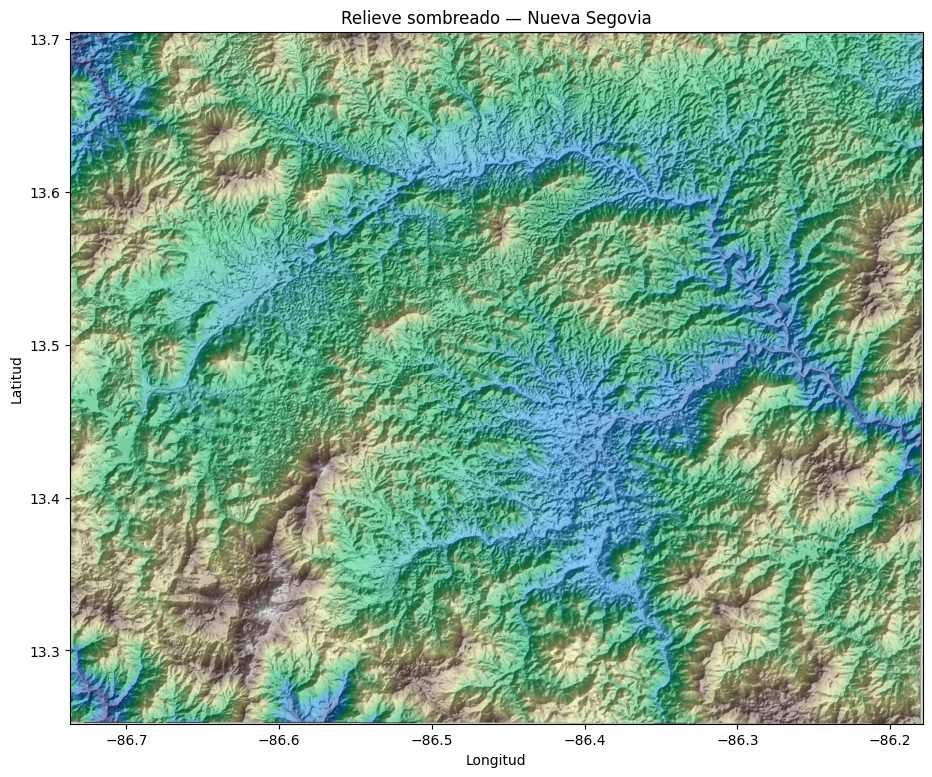

In [ ]:
def relieve_sombreado(elev, azimut=315, altura_sol=45, exageracion=1.0):
    """Sombreado clásico a partir de una matriz de elevaciones."""
    x, y = np.gradient(elev.astype("float32") * exageracion)
    pendiente = np.pi / 2 - np.arctan(np.sqrt(x * x + y * y))
    aspecto = np.arctan2(-x, y)
    az = np.radians(360 - azimut + 90)
    alt = np.radians(altura_sol)
    sombra = (np.sin(alt) * np.sin(pendiente) +
              np.cos(alt) * np.cos(pendiente) * np.cos(az - aspecto))
    return (sombra + 1) / 2


base = np.where(z == nodata, np.nan, z)
hs = relieve_sombreado(np.nan_to_num(base, nan=float(validos.mean()))) ##funcion

plt.figure(figsize=(11, 9))
plt.imshow(hs, cmap="gray", extent=extent)
plt.imshow(zm, cmap="terrain", alpha=0.45, extent=extent)
plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.title("Relieve sombreado — Nueva Segovia")
plt.show()

In [ ]:
#definimos una caja para nuestra area de estudio
R_LON_MIN, R_LON_MAX = -86.55, -86.35
R_LAT_MIN, R_LAT_MAX = 13.35, 13.55

with rasterio.open(DEM_CLASE) as dem:
    ven = from_bounds(R_LON_MIN, R_LAT_MIN, R_LON_MAX, R_LAT_MAX, dem.transform) #toma la caja y los datos georeferenciados

    recorte = dem.read(1, window=ven) ##recortar leyendo directo la banda 1
    # antes leimos la banda completa sin recortar asi -> z = dem.read(1)

    perfil = dem.profile.copy()  #copiamos la metadata del dem original
    perfil.update(height=recorte.shape[0], #actualizamos el recorte con su propia metadata
                  width=recorte.shape[1],
                  transform=dem.window_transform(ven))

print("Original:", z.shape)
print("Recorte :", recorte.shape)

rv = recorte[recorte != nodata]
print(f"\nEn el recorte: mín {rv.min():.0f}  máx {rv.max():.0f}  media {rv.mean():.0f} msnm")

Original: (1672, 2060)
Recorte : (738, 738)

En el recorte: mín 498  máx 1253  media 705 msnm


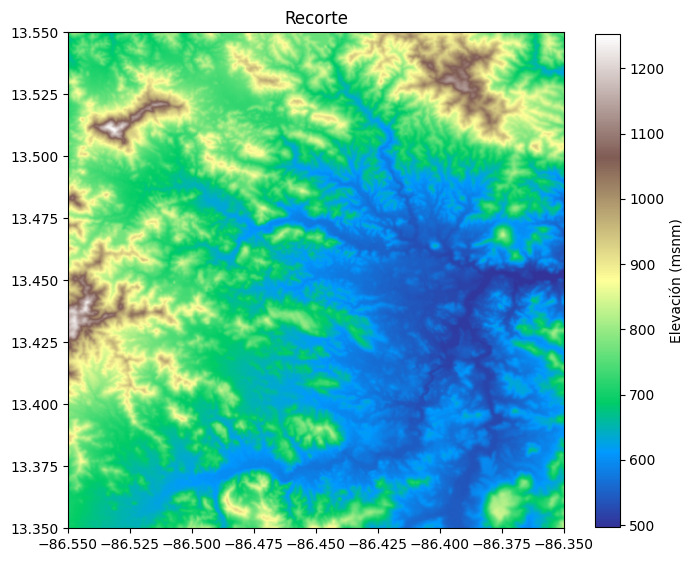

In [ ]:
#vemos el dato recortado
plt.figure(figsize=(8, 8))
plt.imshow(np.ma.masked_equal(recorte, nodata), cmap="terrain",
           extent=[R_LON_MIN, R_LON_MAX, R_LAT_MIN, R_LAT_MAX]) #bounds de la caja
plt.colorbar(label="Elevación (msnm)", shrink=0.8)
plt.title("Recorte")
plt.show()

In [ ]:
#ojo que el profile es importante porque tiene la metadata del raster,
#por eso si lo pensamos guardar tenemos que asegurarnos que es del area recortada
perfil


{'driver': 'GTiff', 'dtype': 'float32', 'nodata': -99999.0, 'width': 738, 'height': 738, 'count': 1, 'crs': CRS.from_wkt('GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST],AUTHORITY["EPSG","4326"]]'), 'transform': Affine(0.0002708826386740877, 0.0, -86.55,
       0.0, -0.0002708826386740877, 13.55), 'blockxsize': 2060, 'blockysize': 1, 'tiled': False, 'interleave': 'band'}

In [ ]:
#ahora asegurados que el perfil es del nuevo raster escribimos un nuevo raster
#asi se graba un raster en rasterio
with rasterio.open("recorte_clase.tif", "w", **perfil) as dst:
    dst.write(recorte, 1) #en vez de open



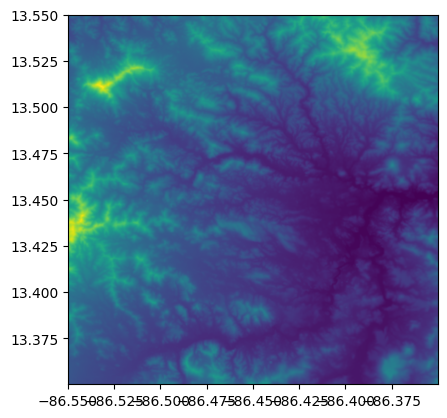

Guardado y verificado
  dimensiones: 738 x 738
  CRS        : EPSG:4326
  valor nulo : -99999.0


In [ ]:
# Verificar: se vuelve a abrir y se compara
with rasterio.open("recorte_clase.tif") as chk:
    show(chk)
    print("Guardado y verificado")
    print("  dimensiones:", chk.width, "x", chk.height)
    print("  CRS        :", chk.crs)
    print("  valor nulo :", chk.nodata)


In [ ]:
print('Bbox del raster',bounds)

Bbox del raster BoundingBox(left=-86.73675055641782, bottom=13.252049445084776, right=-86.17873232074919, top=13.70496521694785)


In [ ]:
est = pd.read_csv("https://raw.githubusercontent.com/navilaufm/python-curso-gis/main/estaciones_region.csv")

dentro = est[(est["latitud"].between(bounds.bottom, bounds.top)) &
             (est["longitud"].between(bounds.left, bounds.right))] #filtrando con los bounds del raster los campos de latitud y longitud

print(f"{len(dentro)} estación(es) dentro del DEM de la clase")
dentro[["nombre", "pais", "latitud", "longitud", "altitud_msnm"]]

1 estación(es) dentro del DEM de la clase


,nombre,pais,latitud,longitud,altitud_msnm
431,Apalí,Nicaragua,13.688,-86.239,675


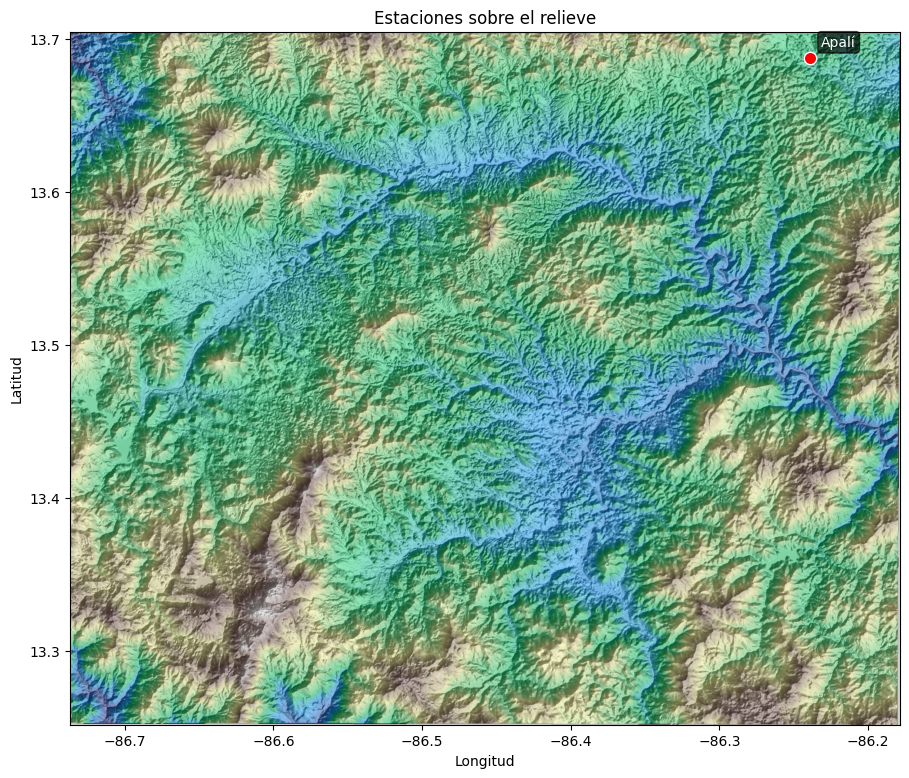

In [ ]:
pts = gpd.GeoDataFrame(
    dentro,
    geometry=gpd.points_from_xy(dentro["longitud"], dentro["latitud"]),
    crs="EPSG:4326"
)

fig, ax = plt.subplots(figsize=(11, 9))
ax.imshow(hs, cmap="gray", extent=extent)
ax.imshow(zm, cmap="terrain", alpha=0.45, extent=extent)
pts.plot(ax=ax, color="red", markersize=80, edgecolor="white")

for r in pts.itertuples():
    ax.annotate(r.nombre, (r.longitud, r.latitud),
                xytext=(8, 8), textcoords="offset points",
                fontsize=10, color="white",
                bbox=dict(boxstyle="round,pad=0.25", fc="black", alpha=0.65))

ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_title("Estaciones sobre el relieve")
plt.show()

In [ ]:
#leer un punto del raster
coords = [(r.longitud, r.latitud) for r in dentro.itertuples()]

with rasterio.open(DEM_CLASE) as dem:
    muestras = [v[0] for v in dem.sample(coords)]

comp = dentro[["latitud","longitud","nombre", "altitud_msnm"]].copy() #creamos una nueva tabla comp con las columnas de dentro, nombre y altitud
comp["dem_msnm"] = np.round(muestras, 0) #agregamos otra columna dem_msnm con la lectura de muestra del dem
comp["diferencia"] = comp["dem_msnm"] - comp["altitud_msnm"] #agregar a dento una nueva columna con la diferencia alt original vs muestra
comp

,latitud,longitud,nombre,altitud_msnm,dem_msnm,diferencia
431,13.688,-86.239,Apalí,675,670.0,-5.0


In [ ]:
#extrear directamente de copernicus


LAT_MIN, LAT_MAX = 14.072137,14.084340    # sur, norte
LON_MIN, LON_MAX = -87.140508,-87.119436  # oeste, este

MI_AREA = "Area de Interés"

print(f"{MI_AREA}: lat {LAT_MIN} a {LAT_MAX} · lon {LON_MIN} a {LON_MAX}")

Area de Interés: lat 14.072137 a 14.08434 · lon -87.140508 a -87.119436


In [ ]:
#leer directamente de la nube
def _url_tesela(lat, lon, glo=30):
    """Dirección del archivo de una tesela de Copernicus."""
    res = "10" if glo == 30 else "30"          # resolución en segundos de arco
    ns = "N" if lat >= 0 else "S"
    ew = "E" if lon >= 0 else "W"
    nombre = (f"Copernicus_DSM_COG_{res}_"
              f"{ns}{abs(lat):02d}_00_{ew}{abs(lon):03d}_00_DEM")
    return f"https://copernicus-dem-{glo}m.s3.amazonaws.com/{nombre}/{nombre}.tif"


def obtener_dem(lat_min, lon_min, lat_max, lon_max):
    """Devuelve el DEM recortado al recuadro: matriz y perfil."""
    teselas = [(la, lo)
               for la in range(math.floor(lat_min), math.floor(lat_max) + 1)
               for lo in range(math.floor(lon_min), math.floor(lon_max) + 1)]

    for glo in (30, 90):
        abiertas = []
        try:
            for la, lo in teselas:
                abiertas.append(rasterio.open(_url_tesela(la, lo, glo)))
        except Exception:
            for a in abiertas:
                a.close()
            print(f"GLO-{glo}: falta al menos una tesela de esta zona.")
            continue

        mosaico, transform = merge(
            abiertas, bounds=(lon_min, lat_min, lon_max, lat_max)
        )
        perfil = abiertas[0].profile.copy()
        for a in abiertas:
            a.close()

        perfil.update(driver="GTiff", count=1,
                      height=mosaico.shape[1], width=mosaico.shape[2],
                      transform=transform)

        print(f"Copernicus GLO-{glo} · {len(teselas)} tesela(s)")
        print(f"{mosaico.shape[2]} x {mosaico.shape[1]} celdas")
        return mosaico[0], perfil

    raise RuntimeError("Esa área no tiene cobertura en GLO-30 ni en GLO-90.")

In [ ]:
#leemos
zi, perfil_i = obtener_dem(LAT_MIN, LON_MIN, LAT_MAX, LON_MAX)

Copernicus GLO-30 · 1 tesela(s)
76 x 44 celdas


In [ ]:
nd_i = perfil_i["nodata"]
vi = zi[zi != nd_i] if nd_i is not None else zi.ravel()

print("CRS        :", perfil_i["crs"])
print("Valor nulo :", nd_i)
print(f"Celda      : {abs(perfil_i['transform'].a) * 111320:.0f} m")
print()
print(f"Mínima  : {vi.min():.0f} msnm")
print(f"Máxima  : {vi.max():.0f} msnm")
print(f"Desnivel: {vi.max() - vi.min():.0f} m")

CRS        : EPSG:4326
Valor nulo : None
Celda      : 31 m

Mínima  : 1177 msnm
Máxima  : 1614 msnm
Desnivel: 437 m


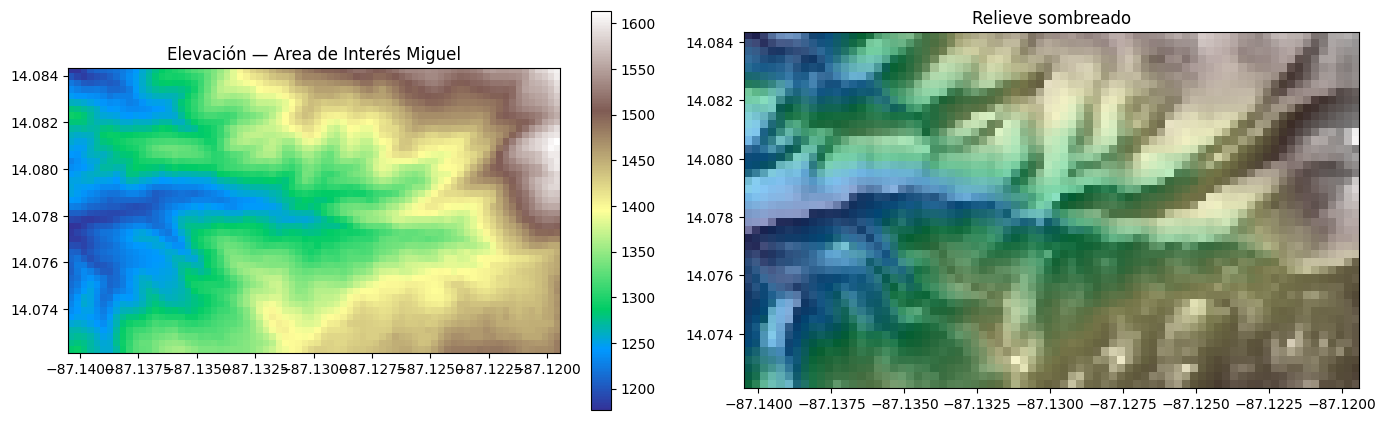

In [ ]:
zmi = np.ma.masked_equal(zi, nd_i) if nd_i is not None else zi
ext_i = [LON_MIN, LON_MAX, LAT_MIN, LAT_MAX]
base_i = np.nan_to_num(np.where(zi == nd_i, np.nan, zi), nan=float(vi.mean()))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

im = ax1.imshow(zmi, cmap="terrain", extent=ext_i)
ax1.set_title(f"Elevación — {MI_AREA}")
plt.colorbar(im, ax=ax1, shrink=0.7)

ax2.imshow(relieve_sombreado(base_i), cmap="gray", extent=ext_i)
ax2.imshow(zmi, cmap="terrain", alpha=0.45, extent=ext_i)
ax2.set_title("Relieve sombreado")

plt.tight_layout()
plt.show()


In [ ]:
SALIDA = "dem_mi_area.tif"

with rasterio.open(SALIDA, "w", **perfil_i) as dst:
    dst.write(zi, 1)

with rasterio.open(SALIDA) as chk:
    print("Guardado:", SALIDA)
    print("  dimensiones:", chk.width, "x", chk.height)
    print("  CRS        :", chk.crs)

Guardado: dem_mi_area.tif
  dimensiones: 76 x 44
  CRS        : EPSG:4326
